![Banner](../images/07_simulation.png)

# Multiple-Point Statistics Simulation (`DirectSampling`, `SNESIM`)

**Datasets:** (1) a synthetic sinuous-channel system, where the truth is known: a 150 × 150 training image, a separate 100 × 100 "true" field and 60 wells; (2) the Jura geology map (`Data/00_shared/data_geostatistics/jura_grid.csv`): its northern half is the training image for the southern half, conditioned on the Jura samples (`jura_data.csv`)

**Library:** `geolattice.geostatistics`: `DirectSampling`, `dssim`, `SNESIM`, `snesim`, `tau_model`, `pattern_histogram`, `pattern_histogram_distance`, `connectivity`, `channel_training_image` (subpackage `geolattice.geostatistics.mps`; GPU engine `geolattice.geostatistics.gpu.mps_gpu`)

**Before this notebook:** [Introduction to geostatistical simulation](05_07_00_introduction_geostatistical_sumulations.ipynb), [sequential indicator co-simulation](05_07_04_sicosim.ipynb) and [plurigaussian simulation](05_07_07_pgs.ipynb).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [Beyond two-point statistics](#beyond-two-point-statistics)
    - 2.2 [Training images and data events](#training-images-and-data-events)
    - 2.3 [SNESIM](#snesim)
    - 2.4 [Direct Sampling](#direct-sampling)
    - 2.5 [Multiple-point co-simulation](#multiple-point-co-simulation)
    - 2.6 [Diagnostics: pattern histograms and connectivity](#diagnostics-pattern-histograms-and-connectivity)
    - 2.7 [The GPU engines](#the-gpu-engines)
    - 2.8 [The algorithms](#the-algorithms)
3. [Python Setup](#python-setup)
4. [A Synthetic Channel System](#a-synthetic-channel-system)
5. [Why Two-Point Statistics Are Not Enough](#why-two-point-statistics-are-not-enough)
6. [Direct Sampling: Parameters](#direct-sampling-parameters)
7. [SNESIM: Multigrid, Patterns and the Servosystem](#snesim-multigrid-patterns-and-the-servosystem)
    - 7.1 [The servosystem trade-off](#the-servosystem-trade-off)
8. [Conditional Simulation against the Truth](#conditional-simulation-against-the-truth)
9. [Multiple-Point Co-Simulation with a Seismic-Like Secondary](#multiple-point-co-simulation-with-a-seismic-like-secondary)
10. [A Continuous Training Image](#a-continuous-training-image)
11. [Real Data: the Jura Geology Map as a Training Image](#real-data-the-jura-geology-map-as-a-training-image)
12. [Visualization of Uncertainty](#visualization-of-uncertainty)
13. [CPU vs GPU Timing](#cpu-vs-gpu-timing)
14. [Summary and Conclusions](#summary-and-conclusions)
    - 14.1 [Choosing the options](#choosing-the-options)
15. [References](#references)

***
## Overview

Every simulator in the earlier notebooks (SGS, SIS, DSS, PGS) is driven by **two-point statistics**: variograms or covariances, which describe how two locations at a given separation relate. Many geological structures are defined by relations among *many* points at once: a channel is a continuous, curving, connected body, and a sequence of units has a specific arrangement. Very different images can share the same variogram, and a two-point simulator will produce the most disordered of them. **Multiple-point statistics** (MPS) simulation takes those relations from a **training image** (TI): a conceptual picture of the expected patterns, such as a sketch, an outcrop, a process-based model, or a mapped analogue area. Each simulated node is drawn according to what the TI shows in the same neighbourhood configuration.

GeoLattice provides the two best-known MPS algorithms:

| Algorithm | Idea | Variables | Notes |
|---|---|---|---|
| **SNESIM** (Strebelle, 2002) | scan the TI once, store every pattern with counts of its centre category; at each node read $P(c \mid \text{data event})$ from the counts | categorical | multigrid; servosystem for proportions; soft data by the tau model |
| **Direct Sampling** (Mariethoz et al., 2010) | at each node, scan the TI from a random position for a pattern close enough to the data event and paste its centre | categorical and continuous | no pattern database; threshold controls fidelity; secondary TI for co-simulation |

The objects:

| Object | What it does |
|---|---|
| `DirectSampling`, `dssim` | Direct Sampling simulator and one-call wrapper |
| `SNESIM`, `snesim` | SNESIM simulator and one-call wrapper |
| `tau_model` | Combines TI and soft probabilities (Journel, 2002) |
| `pattern_histogram`, `pattern_histogram_distance` | Multiple-point histogram of an image, and the distance between two |
| `connectivity` | Probability that two cells of a category at a given lag belong to the same connected body |
| `channel_training_image` | Synthetic sinuous-channel TI |

The notebook first uses a **synthetic channel system**, where the true field is known. It shows why SIS fails on channels, how the parameters of each MPS algorithm act, how conditioning and secondary data help, and how MPS handles continuous variables. It then turns to **real data**: the northern half of the Jura geology map is used as the training image for the southern half. That raises the practical question of every MPS study: is the TI representative?

***
## Theory

### Beyond two-point statistics

A variogram $\gamma(\mathbf{h}) = \tfrac12 E[(Z(\mathbf{u}) - Z(\mathbf{u} + \mathbf{h}))^2]$ involves two points at a time. The **multiple-point** statistics of a categorical image are the probabilities of joint configurations of $n$ points,

$$
P\bigl\{S(\mathbf{u}) = c,\; S(\mathbf{u} + \mathbf{h}_1) = s_1,\; \dots,\; S(\mathbf{u} + \mathbf{h}_n) = s_n\bigr\},
$$

which no variogram model can specify. Two-point simulators fill the gap with the *maximum-entropy* choice implied by kriging, which disperses high values instead of connecting them. Connectivity is precisely what controls flow, contamination pathways or drainage, so this matters in practice.

### Training images and data events

A **training image** $\mathrm{TI}$ is an exhaustive image on the simulation cell size (`ti[ix, iy]`, axis 0 = x). It is assumed **stationary**: its patterns are replicated across it, and it describes the patterns expected in the study area. It need not be conditioned to any data.

At a node $\mathbf{u}$, the **data event** $d_n$ is the set of the $n$ nearest informed nodes, hard data or previously simulated, with their offsets $\mathbf{h}_\alpha$ and values $s_\alpha$. MPS reads the conditional distribution of $S(\mathbf{u})$ from the TI replicates of $d_n$:

$$
P\bigl(S(\mathbf{u}) = c \mid d_n\bigr) = \frac{P(c,\, d_n)}{P(d_n)} \approx \frac{\#\{\mathbf{v} \in \mathrm{TI}: \mathrm{TI}(\mathbf{v}) = c,\; \mathrm{TI}(\mathbf{v} + \mathbf{h}_\alpha) = s_\alpha\ \forall \alpha\}}{\#\{\mathbf{v} \in \mathrm{TI}: \mathrm{TI}(\mathbf{v} + \mathbf{h}_\alpha) = s_\alpha\ \forall \alpha\}} ,
$$

the "single normal equation" of Guardiano & Srivastava (1993). It is the indicator-kriging system written for one $n$-point indicator, whose solution is just this ratio of counts. Sequential simulation along a random path then draws a realization, as in SIS, but with the conditional distribution borrowed from the TI instead of kriged from variograms.

### SNESIM

SNESIM (Strebelle, 2002) makes that practical.

* **Template.** The data event is restricted to a fixed template of the `n_template` nodes nearest the centre within `search_radius` cells.
* **Pattern storage.** For each grid level the TI is scanned **once**, and every unique template pattern is stored with the counts of its centre categories. GeoLattice uses a list-based equivalent of Strebelle's search tree, as in IMPALA (Straubhaar et al., 2011). `n_patterns_` reports how many unique patterns were stored per level.
* **Data-event reduction.** If fewer than `min_replicates` TI patterns match, the farthest informed nodes are dropped until enough do.
* **Multigrid.** Simulation runs from the coarsest grid (spacing $2^{G-1}$ cells, with $G$ = `n_multigrid`) to the finest, with the template stretched by the grid spacing. Large structures are fixed early by a small template, and finer grids fill in details.
* **Servosystem.** To keep the global proportions near the targets $\pi_c$ (`target_proportions`, default the TI proportions), each conditional probability is corrected with the current simulated proportions $\hat\pi_c$:

$$
p_c' = \begin{cases} \max\!\left(0,\; p_c + \frac{\mu}{1 - \mu}\bigl(\pi_c - \hat\pi_c\bigr)\right) & p_c > 0 \\ 0 & p_c = 0 \end{cases}, \quad \text{renormalized}, \qquad \mu = \texttt{servo} \in [0, 1).
$$

  The correction is **additive**, so applied to every category it would give positive probability to a category that the TI says is *impossible* in that data event ($p_c = 0$), creating patterns the TI never shows. GeoLattice therefore corrects only the categories with $p_c > 0$; if nothing is left after clipping, the uncorrected $p_c$ is used. Section 7 checks this on a TI with a strict adjacency rule.

### Direct Sampling

Direct Sampling (Mariethoz, Renard & Straubhaar, 2010) builds no database. At each node it takes the data event (up to `n_neighbors` informed nodes within `search_radius`), then scans the TI **from a random position**, computing a distance between the data event and the TI pattern at each candidate location $\mathbf{v}$:

$$
d\bigl(d_n, \mathrm{TI}(\mathbf{v})\bigr) = \frac{\sum_\alpha w_\alpha\, \delta_\alpha}{\sum_\alpha w_\alpha},
\qquad
\delta_\alpha = \begin{cases} \mathbf{1}[\mathrm{TI}(\mathbf{v} + \mathbf{h}_\alpha) \ne s_\alpha] & \text{categorical} \\ |\mathrm{TI}(\mathbf{v} + \mathbf{h}_\alpha) - s_\alpha| / \text{range}(\mathrm{TI}) & \text{continuous,} \end{cases}
$$

with weights $w_\alpha = |\mathbf{h}_\alpha|^{-\text{distance\_power}}$. The first location with $d \le$ `threshold` is accepted, and its centre value is pasted at $\mathbf{u}$. If `max_scan_fraction` of the TI has been scanned without success, the best match seen is used.

* Scanning from a random start and accepting the first good-enough match amounts to **sampling** from the conditional distribution, without estimating it.
* `threshold` = 0 with many neighbours copies the TI almost verbatim; a larger threshold adds variability and noise.
* `n_postprocess` extra passes re-simulate each non-data node with a fully informed neighbourhood, which removes the noise left by nodes simulated early from sparse data events.
* Because only distances are needed, Direct Sampling handles **continuous** variables too.

### Multiple-point co-simulation

With an exhaustive secondary variable $y$, such as a seismic attribute or a remote-sensing image:

* **Direct Sampling** pairs the TI with a **secondary training image** (`secondary_ti`, for example the same attribute forward-modelled on the TI). The distance becomes
$$
d = (1 - w)\, d_{\text{primary}} + w\, d_{\text{secondary}},
$$
  with $w$ = `secondary_weight`, and $d_{\text{secondary}}$ is computed on the collocated secondary value plus `n_secondary` − 1 template offsets.
* **SNESIM** combines its TI probability $P(c \mid d_n)$ with a soft probability $P(c \mid y)$ through the **tau model** (Journel, 2002). With distances $x = (1 - P)/P$ and $x_0$ from the prior proportions,
$$
\frac{x}{x_0} = \left(\frac{x_{\mathrm{TI}}}{x_0}\right)^{\tau_1} \left(\frac{x_{\text{soft}}}{x_0}\right)^{\tau_2}, \qquad P = \frac{1}{1 + x},
$$
  with $\tau = (1, 1)$ the "permanence of ratios" hypothesis. $\tau_2 = 0$ ignores the soft data and $\tau_1 = 0$ ignores the TI.

### Diagnostics: pattern histograms and connectivity

* The **multiple-point histogram** (`pattern_histogram(image, size)`) counts the frequency of every $s \times s$ configuration. Two images are compared by the total-variation distance $\tfrac12 \sum_p |f_1(p) - f_2(p)|$ (`pattern_histogram_distance`): 0 means identical pattern statistics, 1 disjoint.
* The **connectivity function** (`connectivity(image, c, max_lag, axis)`) is the probability that two cells of category $c$ at lag $h$ along an axis belong to the **same connected body**, given that both are $c$. Connected channels keep it near 1 over long lags; disconnected blobs make it decay quickly.

### The GPU engines

With `use_gpu=True` both simulators run all realizations **in lockstep** with batched array operations (CuPy). SNESIM matches every realization's data event against the pattern table in one fused kernel per step, and gives the same realizations as the CPU engine. Direct Sampling's threads scan TI candidates in parallel. Its realizations are statistically equivalent to the CPU engine's, not bit-identical, because candidates are visited in a different order. The GPU pays off with many realizations.

### The algorithms

**SNESIM**, for each realization:

1. Place the hard data on their nearest nodes.
2. For each grid level, coarse to fine:
    1. visit the uninformed nodes of the level in random order;
    2. read the data event on the stretched template, and reduce it until at least `min_replicates` TI patterns match;
    3. take $P(c \mid d_n)$ from the stored counts; apply the tau model (soft data) and the servosystem;
    4. draw a category.

**Direct Sampling**, for each realization:

1. Place the hard data.
2. Visit the nodes in random order. At each node:
    1. take the data event;
    2. scan the TI from a random position until a pattern is within `threshold` (or the scan budget runs out);
    3. paste its centre value.
3. Optionally re-simulate all non-data nodes (`n_postprocess`).

***
## Python Setup

Both simulators run on the CPU, or on the GPU (CuPy) with `use_gpu=True` / `'auto'`. The setup cell probes the GPU once. The large runs use `use_gpu=USE_GPU`.

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from IPython.display import HTML, display
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import (
    DirectSampling,
    FFTSimulator,
    IndicatorCoSimulator,
    SNESIM,
    channel_training_image,
    connectivity,
    dssim,
    pattern_histogram,
    pattern_histogram_distance,
    snesim,
    tau_model,
)
from geolattice.geostatistics.utils.backend import CUPY_AVAILABLE, cupy_gpu_usable

print("pygstat version:", pygstat.__version__)
USE_GPU = cupy_gpu_usable()
if USE_GPU:
    import cupy as cp
    name = cp.cuda.runtime.getDeviceProperties(0)["name"]
    print("GPU (CuPy)      :", name.decode() if isinstance(name, bytes) else name)
else:
    print("CuPy            :", "installed, but cannot run a kernel here" if CUPY_AVAILABLE else "not installed")
print(f"use_gpu         : {USE_GPU}")

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")


BIN = ListedColormap(["#f2e6c9", "#1f5fa8"])            # background, channel

pygstat version: 0.3.49
GPU (CuPy)      : NVIDIA RTX A5500 Laptop GPU
use_gpu         : True


***
## A Synthetic Channel System

`channel_training_image` draws sinuous channels (1) in a background (0), running along x. The **training image** is a 150 × 150 image; the **truth** is a separate 100 × 100 image from the same generator with a different seed, unknown to the simulators except through 60 randomly placed wells. Cells are one unit wide.

TI channel proportion 0.161;  truth 0.199;  wells in channels: 18 of 60


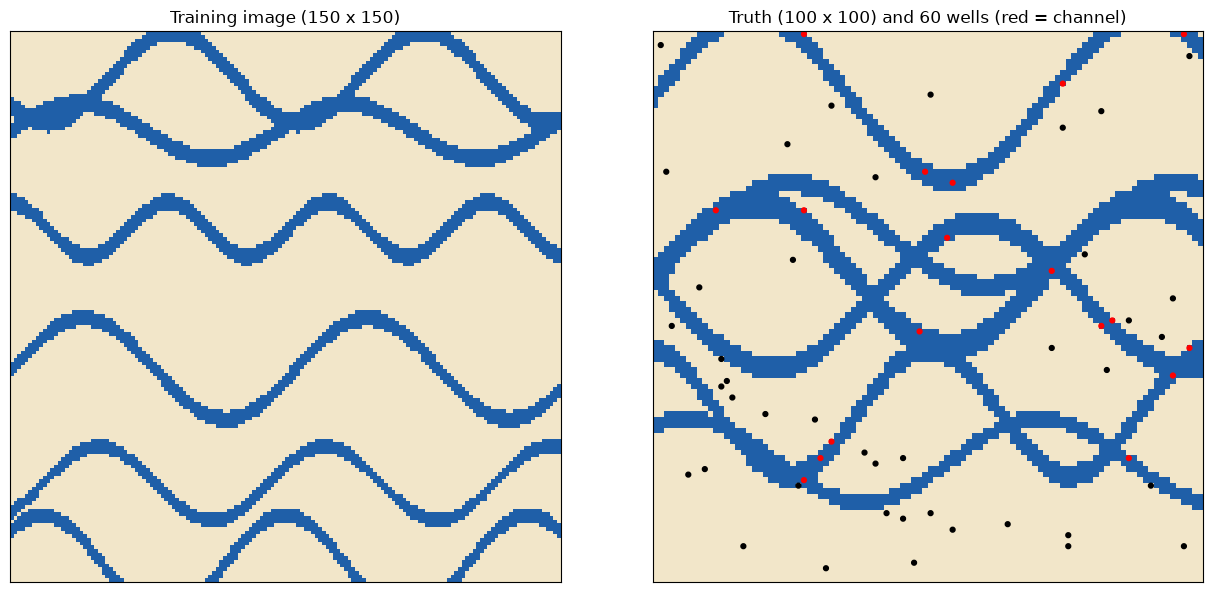

In [2]:
TI = channel_training_image(150, 150, seed=0)
TRUTH = channel_training_image(100, 100, seed=7)
NX = NY = 100
gx, gy = np.meshgrid(np.arange(NX, dtype=float), np.arange(NY, dtype=float), indexing="ij")
grid = np.column_stack([gx.ravel(), gy.ravel()])
truth = TRUTH.ravel()
well_idx = np.random.default_rng(1).choice(len(grid), 60, replace=False)
wells = pd.DataFrame({"X": grid[well_idx, 0], "Y": grid[well_idx, 1], "facies": truth[well_idx]})
print(f"TI channel proportion {TI.mean():.3f};  truth {truth.mean():.3f};  wells in channels: {int(wells.facies.sum())} of 60")


def show_bin(ax, img, title, wells_df=None):
    ax.imshow(np.asarray(img).T, origin="lower", cmap=BIN, vmin=0, vmax=1, interpolation="nearest")
    if wells_df is not None:
        ax.scatter(wells_df.X, wells_df.Y, c=np.where(wells_df.facies == 1, "red", "k"), s=12, marker="o")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(1, 2, figsize=(13, 6))
show_bin(axes[0], TI, "Training image (150 x 150)")
show_bin(axes[1], TRUTH, "Truth (100 x 100) and 60 wells (red = channel)", wells)
plt.tight_layout()
plt.show()

***
## Why Two-Point Statistics Are Not Enough

SIS is given the *exact* indicator variogram of the TI. A spherical model is fitted to the TI's experimental indicator variograms along x and y, which gives a geometric anisotropy with the long range along the channels. Unconditional SIS, SNESIM and Direct Sampling realizations are then compared with the TI on three measures:

* the indicator variogram along each axis;
* the connectivity of channel cells along the channel direction (x);
* the 3 × 3 pattern histogram.

In [3]:
def axis_variogram(img, axis, max_lag=40):
    img = np.asarray(img, float)
    out = []
    for h in range(1, max_lag + 1):
        a = img[:-h, :] if axis == 0 else img[:, :-h]
        b = img[h:, :] if axis == 0 else img[:, h:]
        out.append(0.5 * np.nanmean((a - b) ** 2))
    return np.array(out)


p = TI.mean()
sill = p * (1 - p)
lags = np.arange(1, 41)
sph = lambda h, a: sill * (1.5 * np.minimum(h / a, 1) - 0.5 * np.minimum(h / a, 1) ** 3)
ax_x = curve_fit(sph, lags, axis_variogram(TI, 0), p0=[20])[0][0]
ax_y = curve_fit(sph, lags, axis_variogram(TI, 1), p0=[5])[0][0]
vario_ti = [90.0, 0.0, round(ax_x, 1), round(ax_y, 1), round(sill, 4), "spherical"]   # azimuth 90: major along x
print(f"TI indicator variogram: range along x {ax_x:.1f} cells, along y {ax_y:.1f} cells;  vario = {vario_ti}")

unc = {}
t0 = time.perf_counter()
sis = IndicatorCoSimulator([0, 1], vario_ti, num_points=24, proportions=[1 - p, p], use_gpu=USE_GPU)   # TI proportions
unc["SIS"] = sis.fit(grid, pd.DataFrame({"X": [50.0], "Y": [50.0], "f": [0.0]}), "X", "Y", "f").simulate(
    nsim=10, seed=1).reshape(10, NX, NY)
unc["SNESIM"] = SNESIM(TI, servo=0.0, use_gpu=USE_GPU).fit(grid).simulate_lattice(nsim=10, seed=1)
unc["Direct Sampling"] = DirectSampling(TI, use_gpu=USE_GPU).fit(grid).simulate_lattice(nsim=10, seed=1)
print(f"unconditional realizations in {time.perf_counter() - t0:.0f} s  (SIS uses one dummy datum to start)")

TI indicator variogram: range along x 8.7 cells, along y 5.1 cells;  vario = [90.0, 0.0, np.float64(8.7), np.float64(5.1), np.float64(0.1349), 'spherical']


unconditional realizations in 23 s  (SIS uses one dummy datum to start)


`IndicatorCoSimulator` needs at least one datum, so the SIS run is anchored by a single background datum at the centre, with the TI proportions passed explicitly (otherwise they would be taken from that one datum). SNESIM runs here with `servo=0`, so its results reflect the TI patterns alone; Section 7 looks at the servosystem.

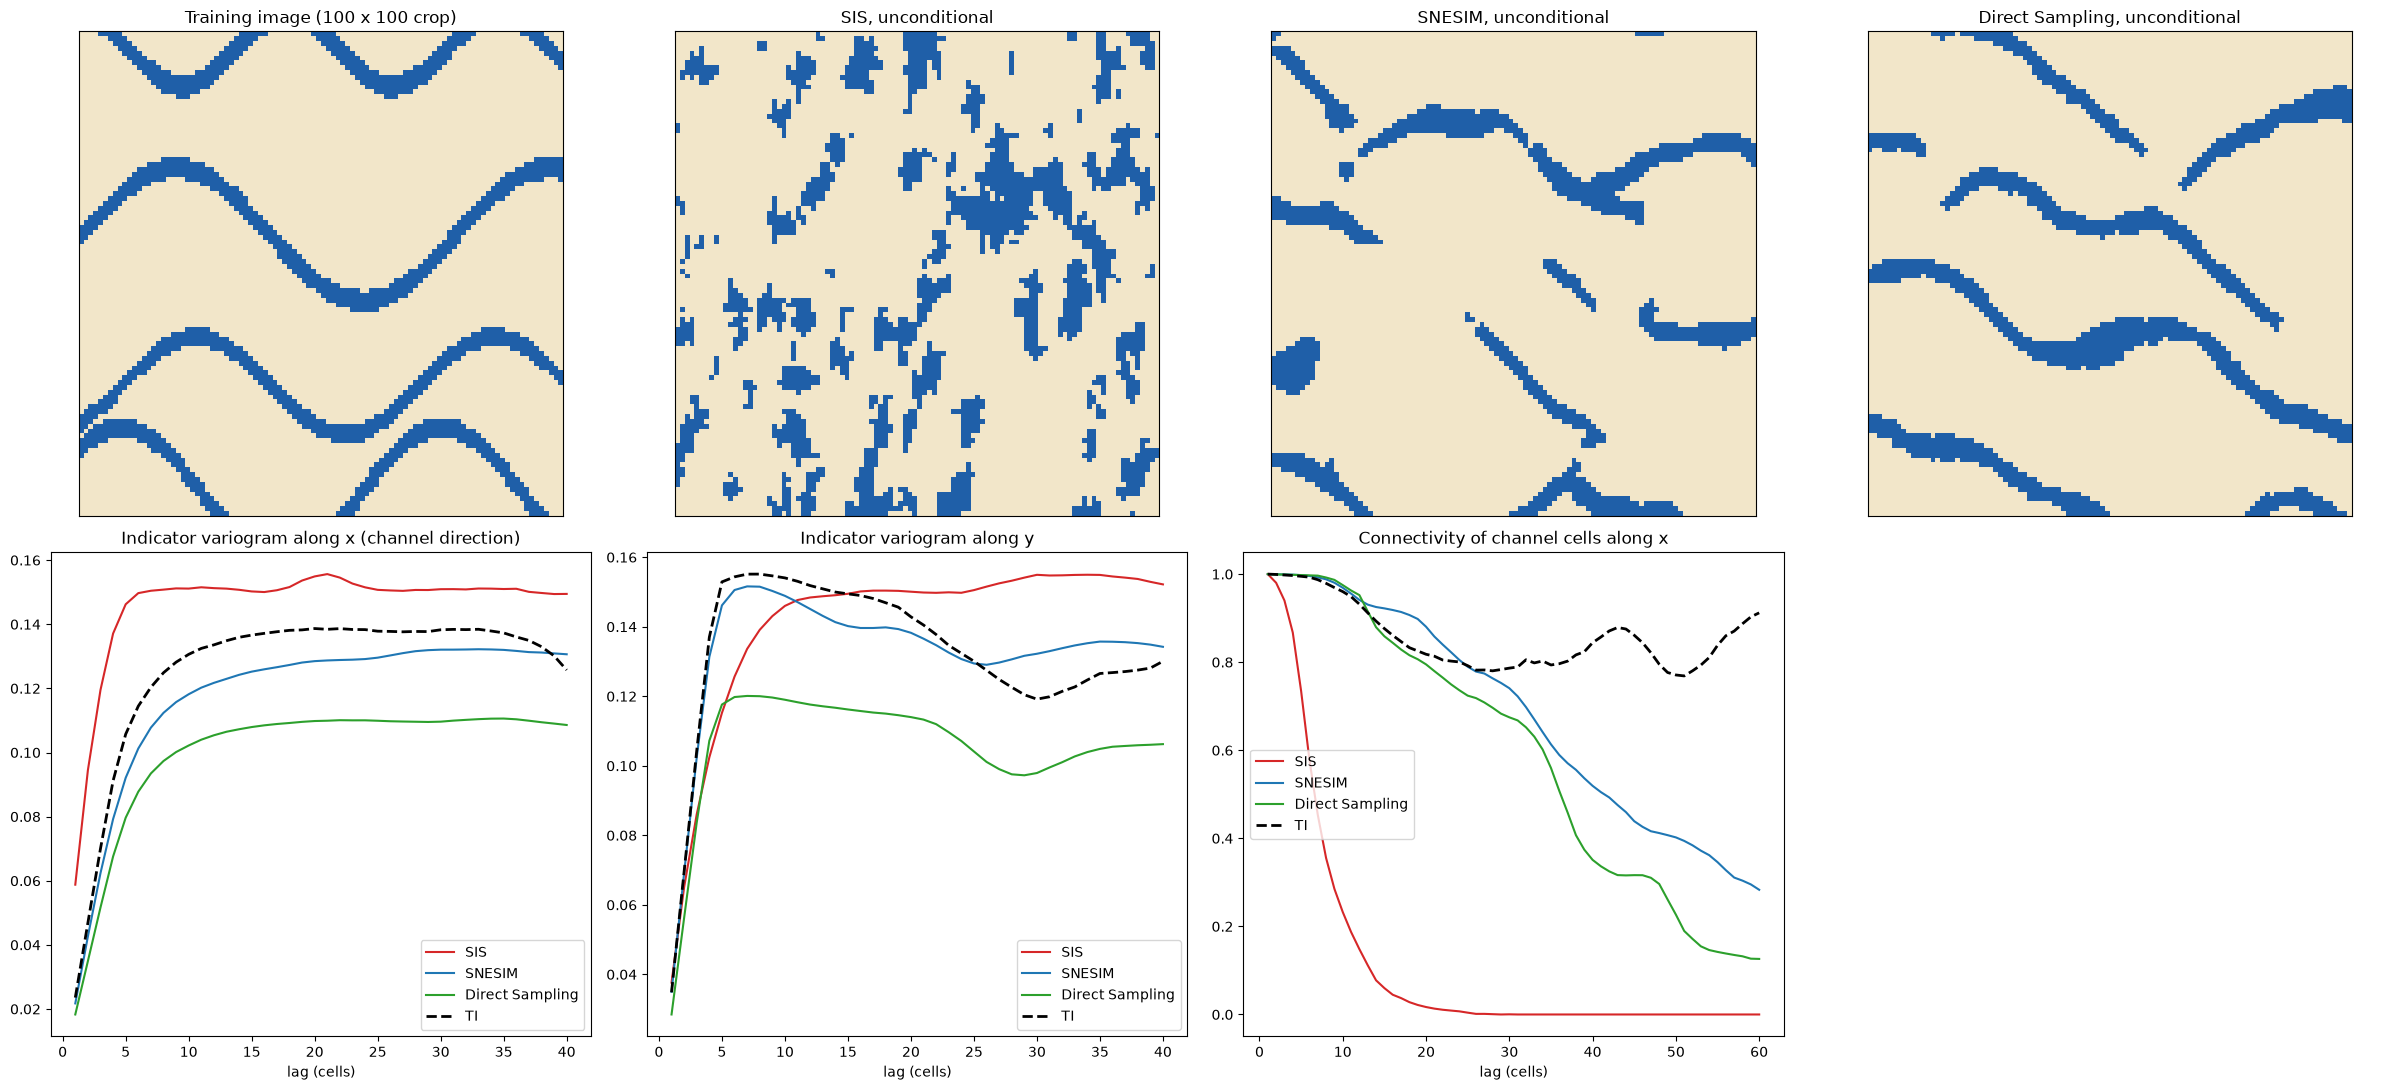

,channel proportion,pattern-histogram distance (3x3),connectivity at 30 cells
method,,,
SIS,0.185,0.225,0.000
SNESIM,0.160,0.062,0.741
Direct Sampling,0.122,0.078,0.675
training image,0.161,0.000,0.786


✅ [PASS] MPS (SNESIM, DS) more connected than SIS at 30 cells  SIS 0.00, SNESIM 0.74, DS 0.67, TI 0.79


In [4]:
ph_ti = pattern_histogram(TI, 3)
conn_ti = connectivity(TI, 1, max_lag=60, axis=0)
fig, axes = plt.subplots(2, 4, figsize=(24, 11))
show_bin(axes[0, 0], TI[:100, :100], "Training image (100 x 100 crop)")
for ax, (name, r) in zip(axes[0, 1:], unc.items()):
    show_bin(ax, r[0], f"{name}, unconditional")

for (name, r), c in zip(unc.items(), ["tab:red", "tab:blue", "tab:green"]):
    axes[1, 0].plot(lags, np.mean([axis_variogram(r[i], 0) for i in range(10)], 0), c=c, label=name)
    axes[1, 1].plot(lags, np.mean([axis_variogram(r[i], 1) for i in range(10)], 0), c=c, label=name)
    axes[1, 2].plot(np.arange(1, 61), np.nanmean([connectivity(r[i], 1, 60, 0) for i in range(10)], 0), c=c, label=name)
axes[1, 0].plot(lags, axis_variogram(TI, 0), "k--", lw=2, label="TI")
axes[1, 1].plot(lags, axis_variogram(TI, 1), "k--", lw=2, label="TI")
axes[1, 2].plot(np.arange(1, 61), conn_ti, "k--", lw=2, label="TI")
axes[1, 0].set_title("Indicator variogram along x (channel direction)")
axes[1, 1].set_title("Indicator variogram along y")
axes[1, 2].set_title("Connectivity of channel cells along x")
for ax in axes[1, :3]:
    ax.set_xlabel("lag (cells)")
    ax.legend()
rows = []
for name, r in unc.items():
    rows.append({"method": name, "channel proportion": r.mean(),
                 "pattern-histogram distance (3x3)": np.mean([pattern_histogram_distance(ph_ti, pattern_histogram(r[i], 3))
                                                               for i in range(10)]),
                 "connectivity at 30 cells": np.nanmean([connectivity(r[i], 1, 30, 0)[-1] for i in range(10)])})
rows.append({"method": "training image", "channel proportion": TI.mean(), "pattern-histogram distance (3x3)": 0.0,
             "connectivity at 30 cells": conn_ti[29]})
two_point = pd.DataFrame(rows).set_index("method")
axes[1, 3].axis("off")
plt.tight_layout()
plt.show()
display(two_point.round(3))
record("MPS (SNESIM, DS) more connected than SIS at 30 cells",
       "PASS" if min(two_point.loc["SNESIM", "connectivity at 30 cells"],
                     two_point.loc["Direct Sampling", "connectivity at 30 cells"]) >
       two_point.loc["SIS", "connectivity at 30 cells"] else "FAIL",
       f"SIS {two_point.loc['SIS', 'connectivity at 30 cells']:.2f}, SNESIM "
       f"{two_point.loc['SNESIM', 'connectivity at 30 cells']:.2f}, DS {two_point.loc['Direct Sampling', 'connectivity at 30 cells']:.2f}, "
       f"TI {conn_ti[29]:.2f}")

* **Two-point statistics look similar.** The indicator variograms of all three simulators have the TI's general shape: a short range across the channels (y) and a longer one along them (x). SIS's are somewhat off; its sill is higher because its channel proportion drifted up (0.19 against 0.16). Nothing in a variogram plot says that one of these images has channels and another has blobs.
* **Multiple-point statistics differ completely.** SIS produces disconnected, irregular patches: the connectivity of channel cells drops to 0 by 30 cells, and its 3 × 3 pattern histogram is far from the TI's (distance 0.23). SNESIM and Direct Sampling produce continuous, sinuous channels: connectivity 0.74 and 0.68 at 30 cells (TI 0.79), and pattern distances of 0.06-0.08.
* **What MPS still misses.** Both MPS methods let channels end more often than the TI does (connectivity falls below the TI's beyond about 30 cells), and Direct Sampling under-produces channel cells (0.12 against 0.16). MPS reproduces patterns up to the template size; very long-range continuity depends on the multigrid (SNESIM) or the search radius (Direct Sampling).

***
## Direct Sampling: Parameters

`threshold` and `n_neighbors` control the trade-off between pattern fidelity and variability; `n_postprocess` cleans early-pass noise. Unconditional runs (5 realizations each) are scored by the 3 × 3 pattern-histogram distance to the TI, the connectivity at 30 cells, and the run time.

,seconds (5 real.),channel proportion,pattern dist. (3x3),connectivity @30
setting,,,,
"thr=0.0, n=30, post=1",3.539,0.131,0.065,0.762
"thr=0.05, n=30, post=1",2.292,0.123,0.074,0.342
"thr=0.2, n=30, post=1",0.978,0.007,0.265,NaN
"thr=0.05, n=10, post=1",0.806,0.151,0.058,0.398
"thr=0.05, n=60, post=1",4.732,0.118,0.088,0.571
"thr=0.05, n=30, post=0",1.486,0.124,0.080,0.504


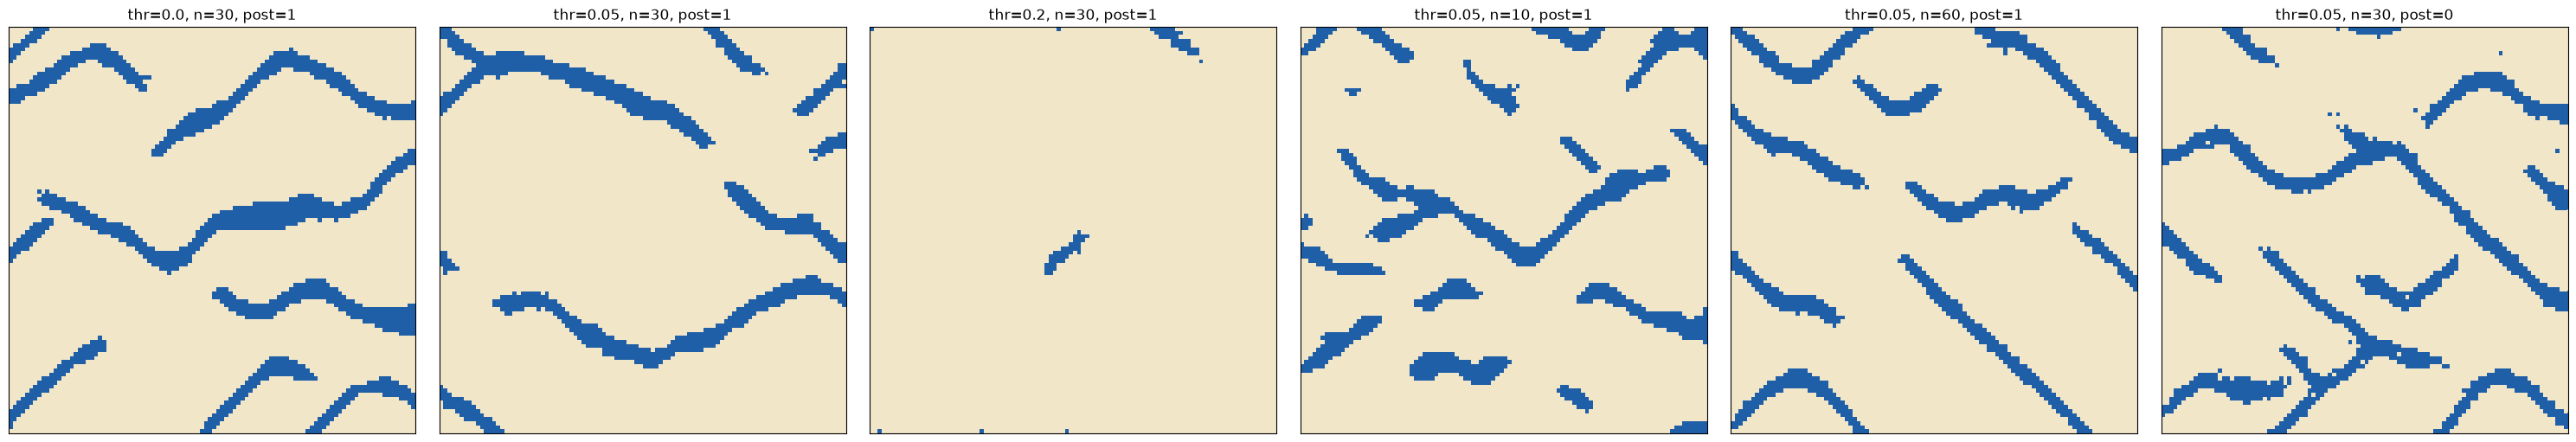

In [5]:
rows, ds_imgs = [], {}
for thr, nn, npp in [(0.0, 30, 1), (0.05, 30, 1), (0.2, 30, 1), (0.05, 10, 1), (0.05, 60, 1), (0.05, 30, 0)]:
    ds = DirectSampling(TI, threshold=thr, n_neighbors=nn, n_postprocess=npp, use_gpu=USE_GPU).fit(grid)
    t0 = time.perf_counter()
    r = ds.simulate_lattice(nsim=5, seed=2)
    sec = time.perf_counter() - t0
    key = f"thr={thr}, n={nn}, post={npp}"
    ds_imgs[key] = r[0]
    rows.append({"setting": key, "seconds (5 real.)": sec, "channel proportion": r.mean(),
                 "pattern dist. (3x3)": np.mean([pattern_histogram_distance(ph_ti, pattern_histogram(r[i], 3)) for i in range(5)]),
                 "connectivity @30": np.nanmean([connectivity(r[i], 1, 30, 0)[-1] for i in range(5)])})
ds_params = pd.DataFrame(rows).set_index("setting")
display(ds_params.round(3))
fig, axes = plt.subplots(1, 6, figsize=(30, 5))
for ax, (k, im_) in zip(axes, ds_imgs.items()):
    show_bin(ax, im_, k)
plt.tight_layout()
plt.show()

* **Threshold.** `threshold = 0` (exact matches only) gives the most TI-like images: the best connectivity (0.76 at 30 cells) and a small pattern distance, at the highest cost. A large threshold (0.2) accepts poor matches. Background patterns are the most common partial matches, so channels die out (channel proportion 0.007): the simulation collapses.
* **Neighbours.** Few neighbours (10) is fast and matches small patterns well (pattern distance 0.058), but long-range continuity is weaker. Many neighbours (60) costs more, and with the default threshold matching becomes harder.
* **Noisy measure.** Connectivity at 30 cells varies a lot between settings and between the 5 realizations behind each value. The post-processing pass, for example, did not improve it here. Judge settings on several realizations and diagnostics, not one number.

Practical defaults: `threshold` 0-0.05, `n_neighbors` 20-40, and `max_scan_fraction` large enough that most nodes find a match.

***
## SNESIM: Multigrid, Patterns and the Servosystem

`n_patterns_` shows how many unique patterns the TI holds at each grid level. Below, the **multigrid** effect on the channel TI is measured: `n_multigrid` = 1 against the default 4, both with `servo=0`.

In [6]:
rows = []
for mg in [1, 2, 4]:
    sn = SNESIM(TI, n_multigrid=mg, servo=0.0, use_gpu=USE_GPU).fit(grid)
    t0 = time.perf_counter()
    r = sn.simulate_lattice(nsim=5, seed=3)
    rows.append({"n_multigrid": mg, "seconds (5 real.)": time.perf_counter() - t0,
                 "patterns stored (finest..coarsest)": sn.n_patterns_,
                 "pattern dist. (3x3)": np.mean([pattern_histogram_distance(ph_ti, pattern_histogram(r[i], 3)) for i in range(5)]),
                 "connectivity @30": np.nanmean([connectivity(r[i], 1, 30, 0)[-1] for i in range(5)]),
                 "channel proportion": r.mean()})
pd.DataFrame(rows).set_index("n_multigrid")

,seconds (5 real.),patterns stored (finest..coarsest),pattern dist. (3x3),connectivity @30,channel proportion
n_multigrid,,,,,
1,0.729846,[2618],0.093057,0.001881,0.13890
2,0.841358,"[2618, 4897]",0.068072,0.399410,0.17858
4,0.918860,"[2618, 4897, 9123, 14513]",0.047040,0.659095,0.15834


The **multigrid** is what makes SNESIM's channels long:

| `n_multigrid` | connectivity at 30 cells | pattern distance |
|---|---|---|
| 1 (40-node template on the finest grid only) | 0.002: channels break into short pieces | 0.093 |
| 2 | 0.40 | 0.068 |
| 4 | 0.66 | 0.047 |

With four levels, the coarse grids lay out the channel paths with a template that spans 8 × 8 = 64 cells, and the finer levels draw them in. Each level stores more unique patterns (2,618 on the finest grid, 14,513 on the coarsest, whose stretched template sees more varied configurations). The run time barely changes.

### The servosystem trade-off

The servosystem keeps proportions close to the target. Applied to every category, its additive correction would revive categories that the TI rules out, so GeoLattice corrects only categories with $p_c > 0$ (Section 2.3). Checking this needs a training image with a strict adjacency rule. A smooth Gaussian field truncated into three ordered classes (A < B < C) has **no** A-C contacts at all, since every path from A to C crosses B. SNESIM is run with increasing `servo`, and Direct Sampling for reference.

TI3 contacts: A-B 1812, B-C 2355, A-C 0;  proportions [0.232, 0.379, 0.389]


,A-C contacts (forbidden),A-B contacts,prop. A,prop. B,prop. C
method,,,,,
SNESIM servo=0,0.0,348.4,0.180,0.375,0.445
SNESIM servo=0.2,0.0,438.4,0.232,0.366,0.402
SNESIM servo=0.5 (default),0.6,464.4,0.234,0.374,0.392
Direct Sampling,0.0,442.8,0.211,0.395,0.395
training image,0.0,453.0,0.232,0.379,0.389


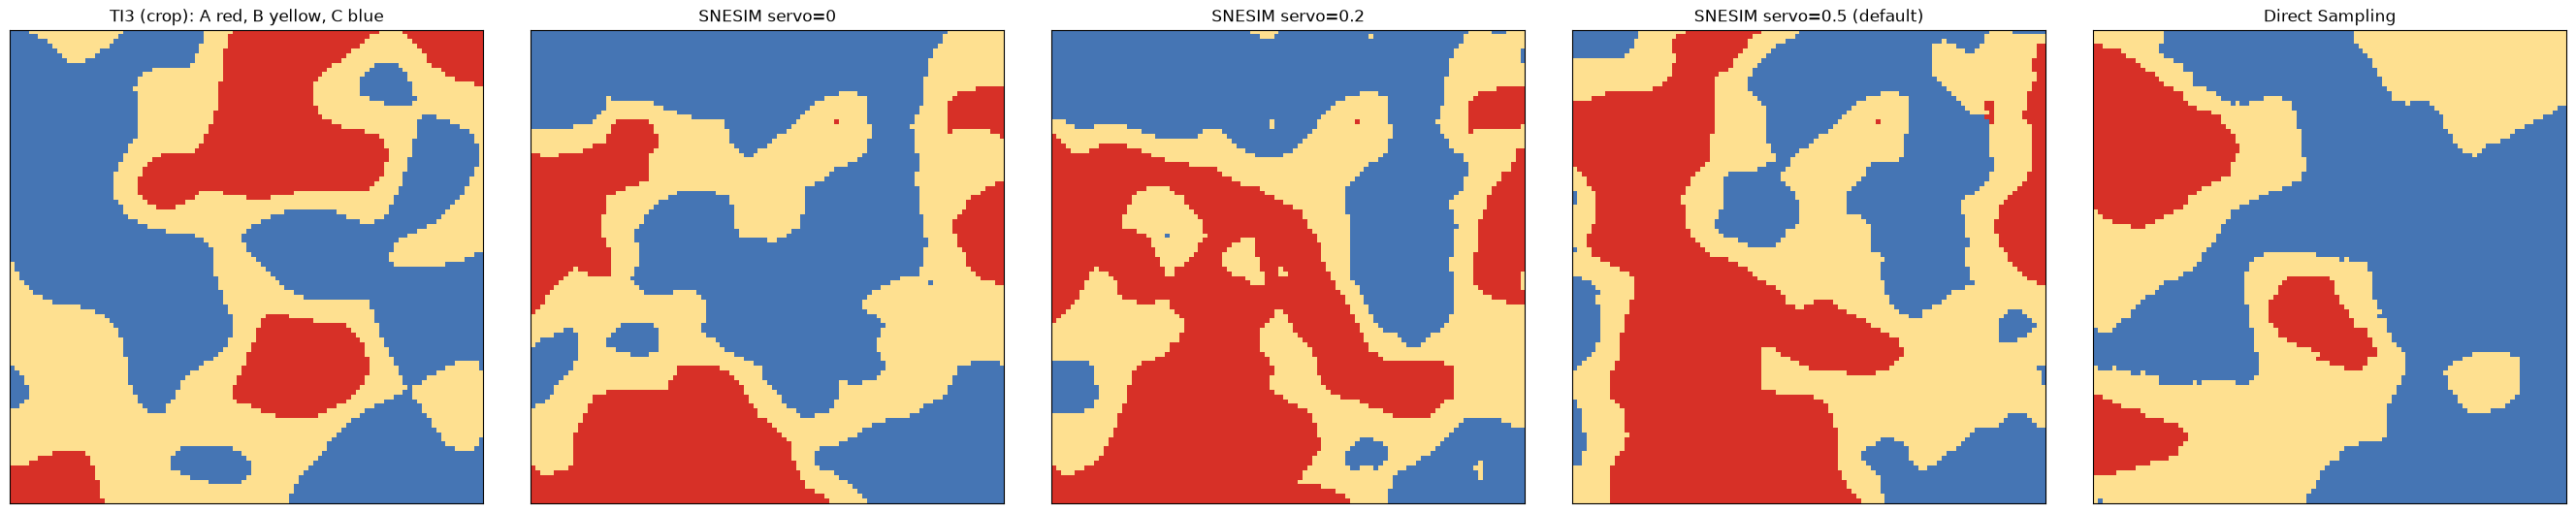

✅ [PASS] SNESIM with servo=0 creates no forbidden A-C contacts  0


In [7]:
gx2, gy2 = np.meshgrid(np.arange(200.0), np.arange(200.0), indexing="ij")
g200 = np.column_stack([gx2.ravel(), gy2.ravel()])
z = FFTSimulator([0, 0, 25, 25, 1, "gaussian"]).fit(g200).simulate(1, seed=3)[0].reshape(200, 200)
TI3 = np.digitize(z, [-0.5, 0.5]).astype(float)           # 0 = A, 1 = B, 2 = C


def contact_counts(img):
    img = np.asarray(img)
    M = np.zeros((3, 3))
    for a, b in [(img[1:, :], img[:-1, :]), (img[:, 1:], img[:, :-1])]:
        ok = a != b
        np.add.at(M, (a[ok].astype(int), b[ok].astype(int)), 1)
    return M + M.T


M_ti = contact_counts(TI3)
print(f"TI3 contacts: A-B {M_ti[0, 1]:.0f}, B-C {M_ti[1, 2]:.0f}, A-C {M_ti[0, 2]:.0f};  proportions "
      f"{[round(float(np.mean(TI3 == k)), 3) for k in range(3)]}")

rows, servo_imgs = [], {}
for name, sim in [("SNESIM servo=0", SNESIM(TI3, servo=0.0, use_gpu=USE_GPU)),
                  ("SNESIM servo=0.2", SNESIM(TI3, servo=0.2, use_gpu=USE_GPU)),
                  ("SNESIM servo=0.5 (default)", SNESIM(TI3, servo=0.5, use_gpu=USE_GPU)),
                  ("Direct Sampling", DirectSampling(TI3, use_gpu=USE_GPU))]:
    r = sim.fit(grid).simulate_lattice(nsim=5, seed=1)
    servo_imgs[name] = r[0]
    Ms = [contact_counts(r[i]) for i in range(5)]
    rows.append({"method": name, "A-C contacts (forbidden)": np.mean([M[0, 2] for M in Ms]),
                 "A-B contacts": np.mean([M[0, 1] for M in Ms]),
                 **{f"prop. {c}": np.mean(r == k) for k, c in enumerate("ABC")}})
rows.append({"method": "training image", "A-C contacts (forbidden)": 0.0, "A-B contacts": M_ti[0, 1] / 4,
             **{f"prop. {c}": np.mean(TI3 == k) for k, c in enumerate("ABC")}})
servo_table = pd.DataFrame(rows).set_index("method")
display(servo_table.round(3))
cm3 = ListedColormap(["#d73027", "#fee090", "#4575b4"])
fig, axes = plt.subplots(1, 5, figsize=(27, 5.2))
axes[0].imshow(TI3[:100, :100].T, origin="lower", cmap=cm3, vmin=0, vmax=2)
axes[0].set_title("TI3 (crop): A red, B yellow, C blue")
for ax, (k, im_) in zip(axes[1:], servo_imgs.items()):
    ax.imshow(im_.T, origin="lower", cmap=cm3, vmin=0, vmax=2, interpolation="nearest")
    ax.set_title(k)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()
record("SNESIM with servo=0 creates no forbidden A-C contacts", "PASS" if servo_table.loc["SNESIM servo=0", "A-C contacts (forbidden)"] == 0
       else "FAIL", f"{servo_table.loc['SNESIM servo=0', 'A-C contacts (forbidden)']:.0f}")

This is the trade-off in numbers:

| | forbidden A-C contacts per realization | proportion of A (target 0.232) |
|---|---|---|
| `servo = 0` | 0 | 0.18 (C rises to 0.45) |
| `servo = 0.2` | 0 | 0.23 |
| `servo = 0.5` (default) | 0.6 | 0.23 |
| Direct Sampling | 0 | 0.21 |

* **`servo = 0`** reproduces the TI's adjacency rule, but the proportions drift.
* **`servo > 0`** pulls the proportions onto the targets *and* keeps the adjacency rule, because only categories the TI allows in the data event are corrected. An unmasked additive correction, which gives A or C probability where the TI says it is impossible, produced 213 (`servo = 0.2`) and 389 (`servo = 0.5`) A-C contacts per realization on this TI.
* The occasional A-C contact that remains (about 3 edges over 5 realizations) is not caused by the servosystem. When fewer than `min_replicates` TI patterns match, the farthest data-event nodes are dropped, and the reduced event can allow A next to C. `servo = 0` produces such contacts too with other seeds.
* **Direct Sampling**, which has no servosystem, has no forbidden contacts and proportions close to the TI's.

The servosystem can be left on when adjacency rules matter, but check contacts and proportions on the realizations. The rest of this notebook uses `servo = 0` unless stated otherwise, so that SNESIM's results reflect the TI patterns alone.


***
## Conditional Simulation against the Truth

Now the simulators are conditioned on the 60 wells and compared with the true field. A trivial "all background" map would agree with 80% of the cells, so cell agreement is a poor score. The measures used are:

* **channel recall** and **precision** of the most probable map;
* the **Brier score** of the channel probability $P(\text{channel})$;
* **connectivity** and **pattern-histogram distance** relative to the truth;
* exact reproduction of the wells.

20 realizations per method; SNESIM uses `servo=0`.

,seconds,wells honoured,channel proportion,recall,precision,Brier,pattern dist. to truth,connectivity @30
method,,,,,,,,
SIS,24.608,True,0.310,0.159,0.462,0.170,0.341,0.024
SNESIM,1.040,True,0.195,0.211,0.553,0.148,0.083,0.752
Direct Sampling,4.235,True,0.133,0.152,0.759,0.148,0.130,0.652
truth,NaN,NaN,0.199,1.000,1.000,0.000,0.000,0.891


✅ [PASS] SIS: wells honoured in every realization  
✅ [PASS] SNESIM: wells honoured in every realization  
✅ [PASS] Direct Sampling: wells honoured in every realization  


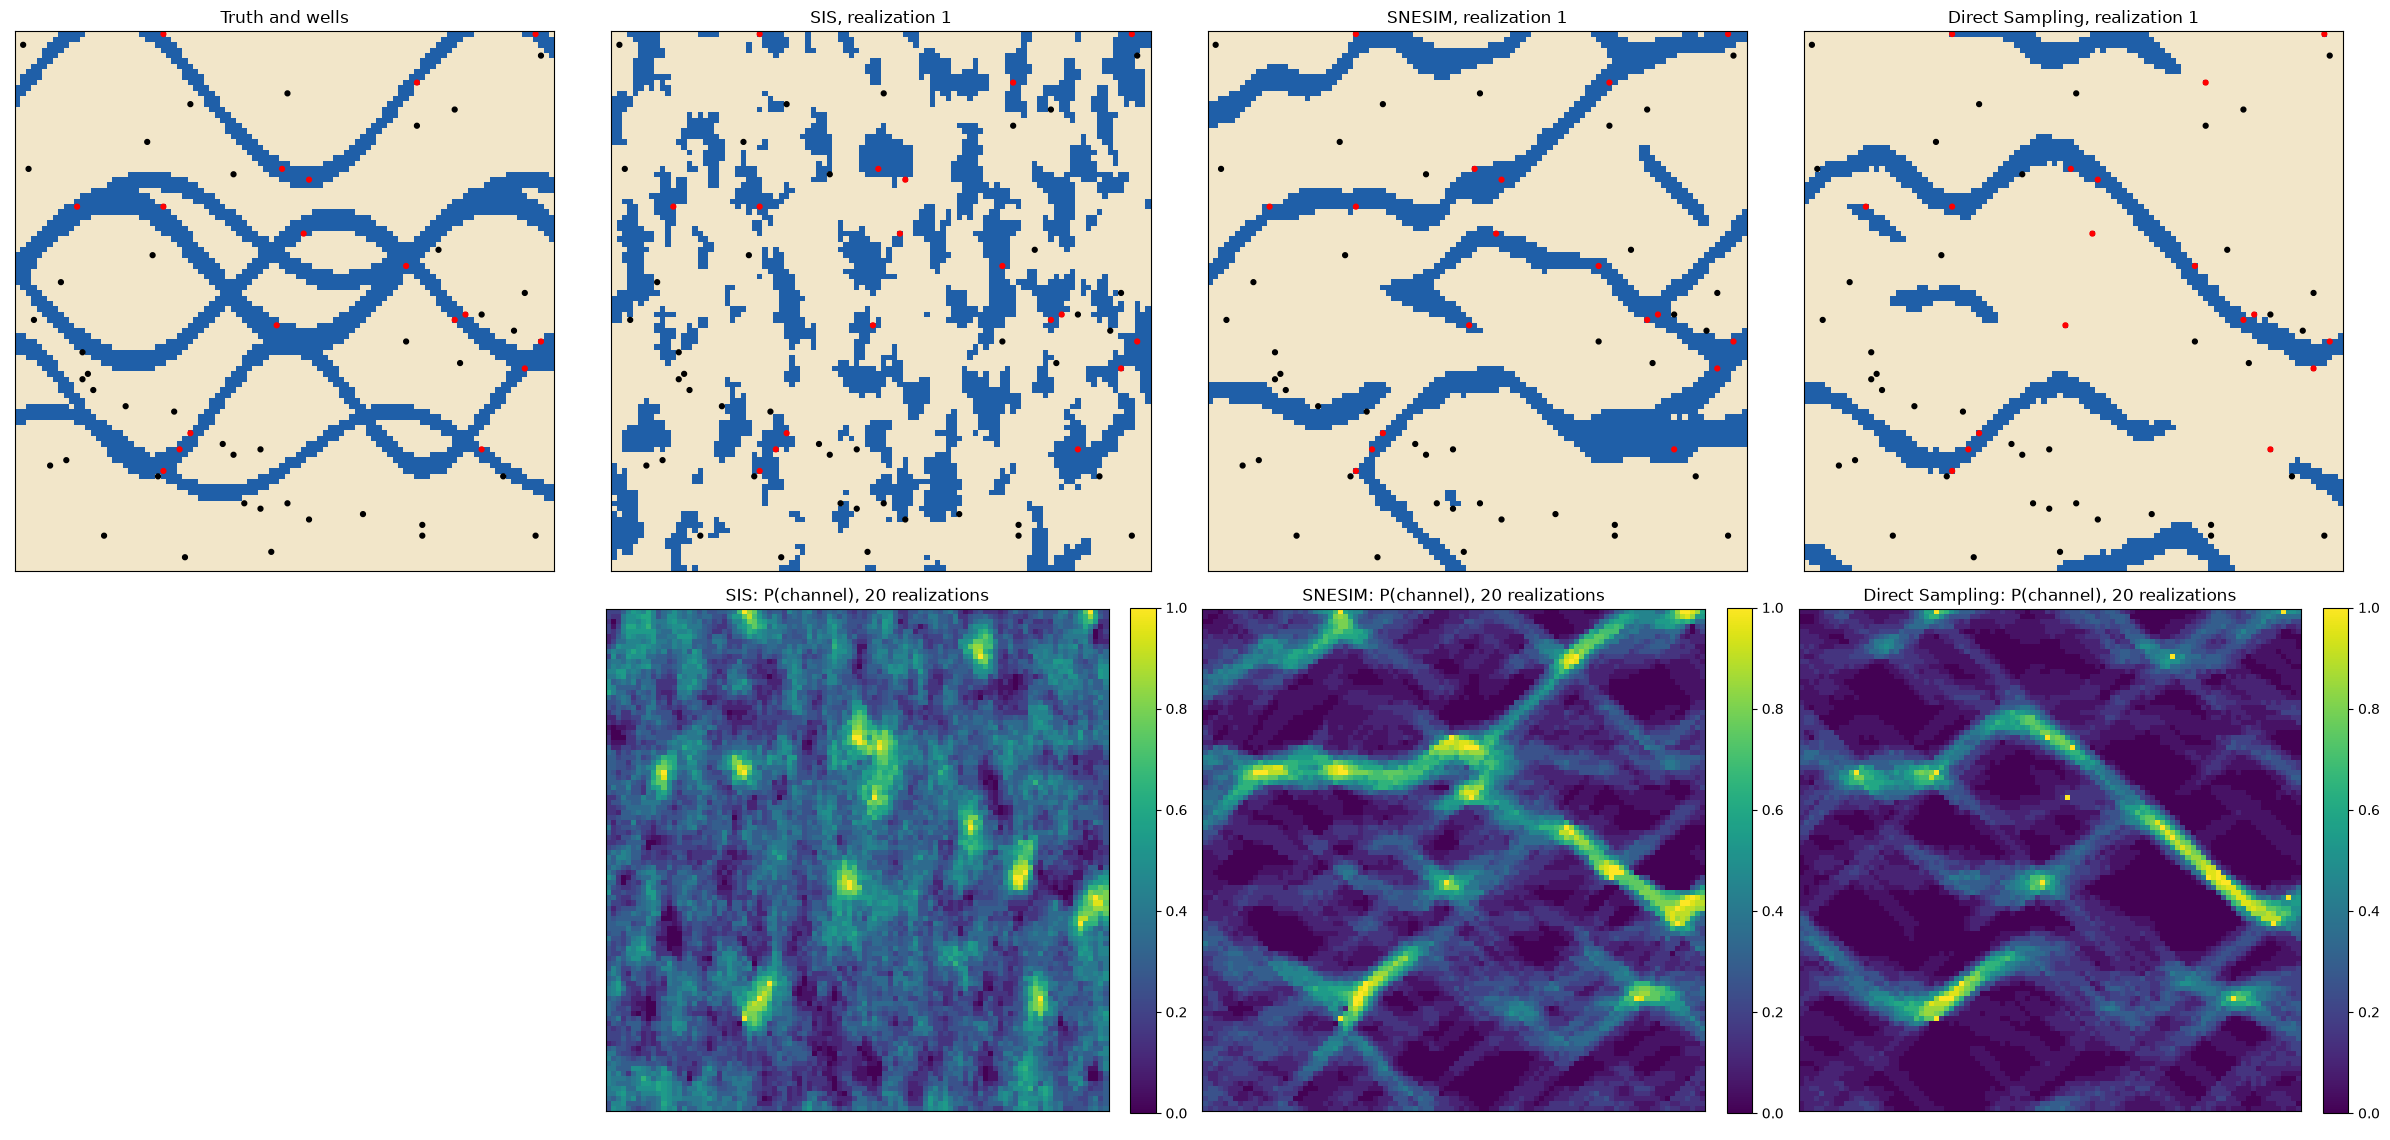

In [8]:
N_SIM = 20
cond = {}
times = {}
for name, sim in [("SIS", IndicatorCoSimulator([0, 1], vario_ti, num_points=24, use_gpu=USE_GPU)),
                  ("SNESIM", SNESIM(TI, servo=0.0, use_gpu=USE_GPU)),
                  ("Direct Sampling", DirectSampling(TI, use_gpu=USE_GPU))]:
    t0 = time.perf_counter()
    cond[name] = sim.fit(grid, wells, "X", "Y", "facies").simulate(nsim=N_SIM, seed=5)
    times[name] = time.perf_counter() - t0

ph_truth = pattern_histogram(TRUTH, 3)
conn_truth = connectivity(TRUTH, 1, 30, 0)[-1]
rows = []
for name, r in cond.items():
    p_ch = r.mean(0)
    mode = (p_ch > 0.5).astype(float)
    tp = np.sum((mode == 1) & (truth == 1))
    rows.append({"method": name, "seconds": times[name],
                 "wells honoured": bool(np.all(r[:, well_idx] == wells.facies.to_numpy()[None, :])),
                 "channel proportion": r.mean(), "recall": tp / truth.sum(), "precision": tp / max(mode.sum(), 1),
                 "Brier": np.mean((p_ch - truth) ** 2),
                 "pattern dist. to truth": np.mean([pattern_histogram_distance(ph_truth, pattern_histogram(r[i].reshape(NX, NY), 3))
                                                    for i in range(N_SIM)]),
                 "connectivity @30": np.nanmean([connectivity(r[i].reshape(NX, NY), 1, 30, 0)[-1] for i in range(N_SIM)])})
rows.append({"method": "truth", "channel proportion": truth.mean(), "recall": 1.0, "precision": 1.0, "Brier": 0.0,
             "pattern dist. to truth": 0.0, "connectivity @30": conn_truth})
cond_table = pd.DataFrame(rows).set_index("method")
display(cond_table.round(3))
for name in cond:
    record(f"{name}: wells honoured in every realization", "PASS" if cond_table.loc[name, "wells honoured"] else "FAIL")

fig, axes = plt.subplots(2, 4, figsize=(24, 11.5))
show_bin(axes[0, 0], TRUTH, "Truth and wells", wells)
for j, (name, r) in enumerate(cond.items()):
    show_bin(axes[0, j + 1], r[0].reshape(NX, NY), f"{name}, realization 1", wells)
    im = axes[1, j + 1].imshow(r.mean(0).reshape(NX, NY).T, origin="lower", cmap="viridis", vmin=0, vmax=1)
    axes[1, j + 1].set_title(f"{name}: P(channel), {N_SIM} realizations")
    axes[1, j + 1].set_xticks([])
    axes[1, j + 1].set_yticks([])
    plt.colorbar(im, ax=axes[1, j + 1], fraction=0.046, pad=0.04)
axes[1, 0].axis("off")
plt.tight_layout()
plt.show()

* **All three honour the wells exactly.**
* **MPS reproduces the patterns of the true field.** Pattern distance to the truth is 0.08 (SNESIM) and 0.13 (Direct Sampling), against 0.34 for SIS. Connectivity at 30 cells is 0.75 and 0.65, against 0.02 for SIS and 0.89 for the truth. SIS's realizations are blobs, and it over-produces channel cells (0.31 against 0.20), because its proportion comes from the wells.
* **Local prediction is weak for everyone.** 60 wells in 10,000 cells do not say where the channels are between wells. The channel probability maps are diffuse, and the most probable map recovers only 15-21% of the channel cells. MPS improves the Brier score (0.148 against 0.170) and the precision, but the main gain is *structural*. The realizations look and connect like the real system, which is what matters for anything that depends on connectivity, such as flow and transport. The next section shows how a secondary variable sharpens the local picture.

***
## Multiple-Point Co-Simulation with a Seismic-Like Secondary

A **secondary** variable known everywhere, but blurred and noisy, is built by smoothing the facies with a Gaussian filter ($\sigma$ = 3 cells) and adding noise, like a low-resolution seismic attribute. The same operator applied to the TI gives the **secondary training image**.

* **Direct Sampling:** `secondary_ti` plus the secondary on the grid, with `secondary_weight` 0.5.
* **SNESIM:** soft probabilities $P(\text{channel} \mid y)$ calibrated on the TI pairs (20 quantile bins of the secondary TI), combined with the TI probabilities by the **tau model**.

corr(secondary, facies): TI 0.68, truth 0.64
tau_model example: prior 0.16, TI 0.5, soft 0.7 -> 0.925


,recall,precision,Brier,agreement per realization,connectivity @30
method,,,,,
SNESIM,0.211,0.553,0.148,0.732,0.752
Direct Sampling,0.152,0.759,0.148,0.764,0.652
DS + secondary TI,0.773,0.799,0.058,0.891,0.889
SNESIM + soft (tau model),0.501,0.729,0.093,0.840,0.672


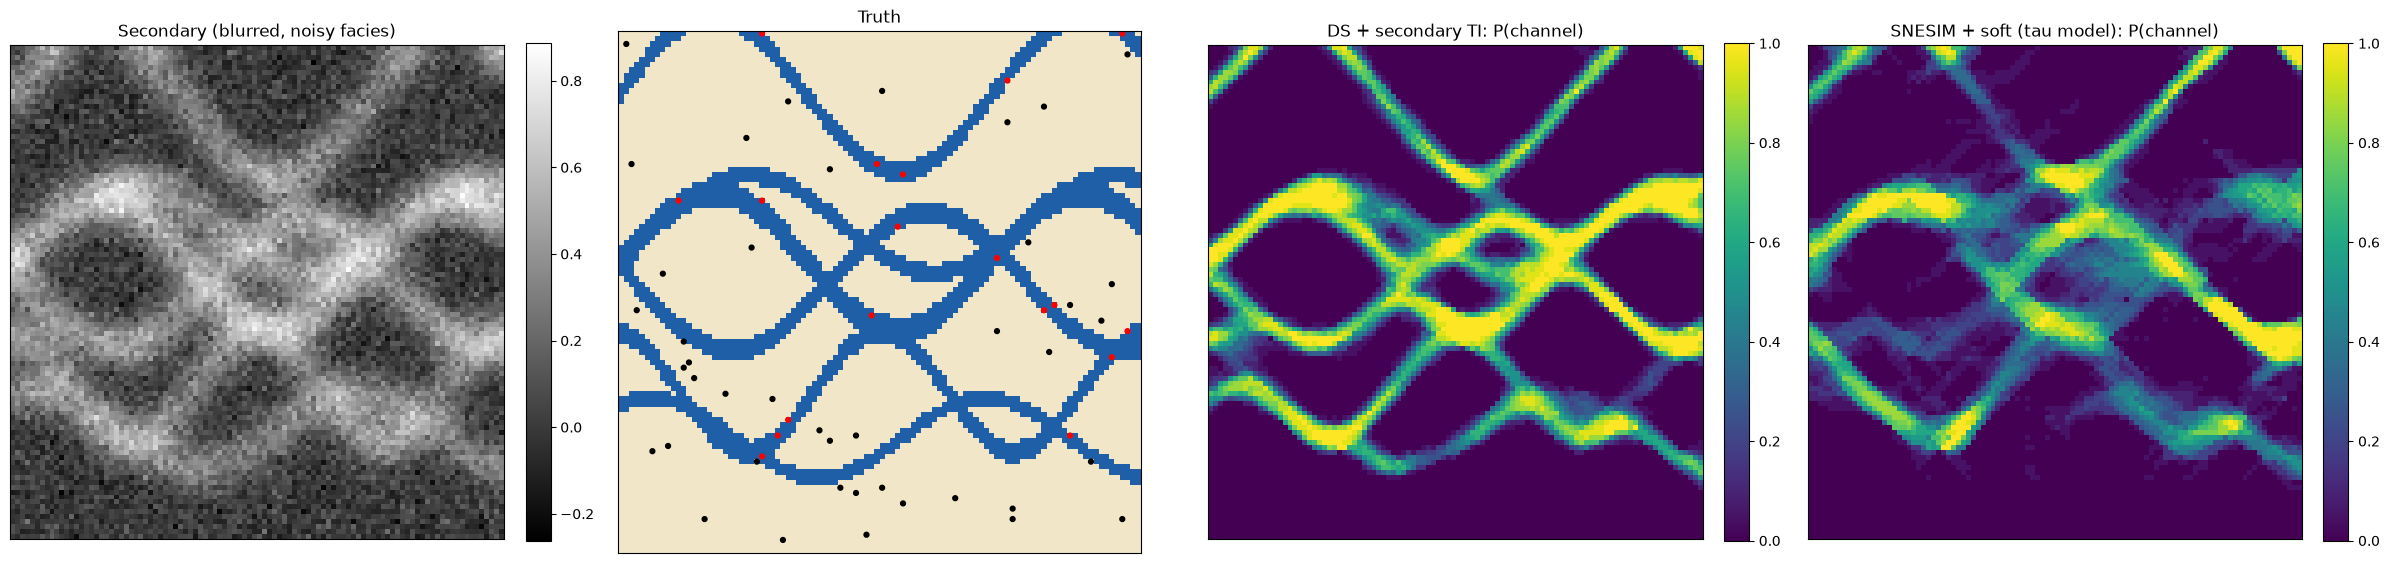

✅ [PASS] co-simulation lowers the Brier score (DS and SNESIM)  DS 0.148 -> 0.058; SNESIM 0.148 -> 0.093


In [9]:
def seismic(img, seed):
    return gaussian_filter(np.asarray(img, float), 3.0) + np.random.default_rng(seed).normal(0, 0.08, np.shape(img))


SEC_TI = seismic(TI, 10)
sec_grid = seismic(TRUTH, 11).ravel()
print(f"corr(secondary, facies): TI {np.corrcoef(SEC_TI.ravel(), TI.ravel())[0, 1]:.2f}, "
      f"truth {np.corrcoef(sec_grid, truth)[0, 1]:.2f}")

# soft probabilities for SNESIM: calibrate P(channel | secondary) on the TI pairs
edges = np.quantile(SEC_TI, np.linspace(0, 1, 21))
b_ti = np.clip(np.searchsorted(edges, SEC_TI.ravel(), side="right") - 1, 0, 19)
p_bin = np.array([TI.ravel()[b_ti == b].mean() for b in range(20)])
b_grid = np.clip(np.searchsorted(edges, sec_grid, side="right") - 1, 0, 19)
soft = np.column_stack([1 - p_bin[b_grid], p_bin[b_grid]])        # columns in categories_ order: 0, 1

print("tau_model example: prior 0.16, TI 0.5, soft 0.7 ->",
      np.round(tau_model(np.array([0.84, 0.16]), np.array([0.5, 0.5]), np.array([0.3, 0.7]))[1], 3))

cosim = {
    "DS + secondary TI": DirectSampling(TI, secondary_ti=SEC_TI, secondary_weight=0.5, use_gpu=USE_GPU).fit(
        grid, wells, "X", "Y", "facies", secondary=sec_grid).simulate(nsim=N_SIM, seed=5),
    "SNESIM + soft (tau model)": SNESIM(TI, servo=0.0, use_gpu=USE_GPU).fit(
        grid, wells, "X", "Y", "facies", soft=soft).simulate(nsim=N_SIM, seed=5),
}
rows = []
for name, r in list(cond.items())[1:] + list(cosim.items()):
    p_ch = r.mean(0)
    mode = (p_ch > 0.5).astype(float)
    tp = np.sum((mode == 1) & (truth == 1))
    rows.append({"method": name, "recall": tp / truth.sum(), "precision": tp / max(mode.sum(), 1),
                 "Brier": np.mean((p_ch - truth) ** 2), "agreement per realization": np.mean(r == truth[None, :]),
                 "connectivity @30": np.nanmean([connectivity(r[i].reshape(NX, NY), 1, 30, 0)[-1] for i in range(N_SIM)])})
co_table = pd.DataFrame(rows).set_index("method")
display(co_table.round(3))

fig, axes = plt.subplots(1, 4, figsize=(24, 5.6))
im = axes[0].imshow(sec_grid.reshape(NX, NY).T, origin="lower", cmap="gray")
axes[0].set_title("Secondary (blurred, noisy facies)")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
show_bin(axes[1], TRUTH, "Truth", wells)
for ax, (name, r) in zip(axes[2:], cosim.items()):
    im = ax.imshow(r.mean(0).reshape(NX, NY).T, origin="lower", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"{name}: P(channel)")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()
record("co-simulation lowers the Brier score (DS and SNESIM)",
       "PASS" if co_table.loc["DS + secondary TI", "Brier"] < co_table.loc["Direct Sampling", "Brier"] and
       co_table.loc["SNESIM + soft (tau model)", "Brier"] < co_table.loc["SNESIM", "Brier"] else "FAIL",
       f"DS {co_table.loc['Direct Sampling', 'Brier']:.3f} -> {co_table.loc['DS + secondary TI', 'Brier']:.3f}; SNESIM "
       f"{co_table.loc['SNESIM', 'Brier']:.3f} -> {co_table.loc['SNESIM + soft (tau model)', 'Brier']:.3f}")

* **A secondary variable changes local prediction dramatically.** The secondary is blurred and noisy, with a correlation of only 0.64 with the facies.
    * **Direct Sampling with the secondary TI** recovers 77% of the channel cells with 80% precision. Its Brier score falls from 0.148 to 0.058, and connectivity at 30 cells (0.89) matches the truth's (0.89). Matching the secondary *pattern* around each node uses the spatial structure of the blur, not just the collocated value.
    * **SNESIM with tau-model soft probabilities** also improves (Brier 0.093, recall 0.50), but less. Its soft probability uses only the collocated secondary value, through a calibration curve.
* **The tau model** with $\tau = (1, 1)$ is conditional independence in odds form. With prior 0.16, TI 0.5 and soft 0.7, it gives 0.93: two moderately informative, independent sources reinforce each other strongly. If the sources are redundant, $\tau < 1$ tempers that.

***
## A Continuous Training Image

Direct Sampling also works for **continuous** variables, using the mean absolute difference as the distance. The training image here is a continuous field with a non-Gaussian pattern: the absolute value of a smooth Gaussian field. That gives sharp, narrow valleys between rounded highs, a ridge-valley structure that a variogram alone cannot describe. Unconditional realizations are compared with the TI on the histogram, the variogram along x, and the visual pattern.

continuous DS: 5 realizations in 9.9 s; kind = continuous


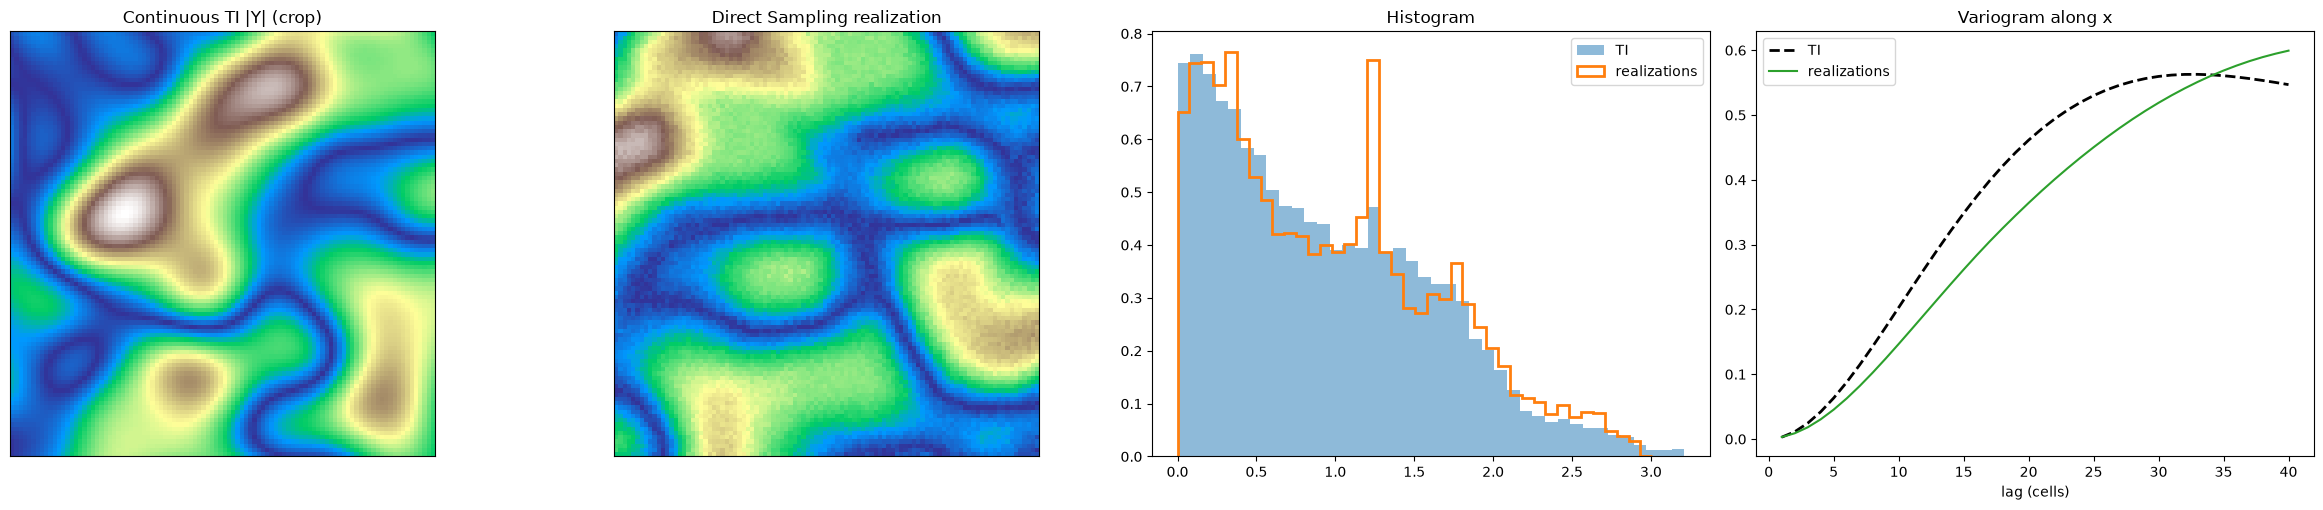

TI mean 0.932, sd 0.681;  realizations mean 0.957, sd 0.691;  lag-1 variogram ratio realization/TI 1.08


In [10]:
g150 = np.column_stack([np.repeat(np.arange(150.0), 150), np.tile(np.arange(150.0), 150)])
zc = FFTSimulator([0, 0, 30, 30, 1, "gaussian"]).fit(g150).simulate(1, seed=9)[0]
TI_C = np.abs(zc.reshape(150, 150))
dsc = DirectSampling(TI_C, kind="continuous", n_neighbors=30, threshold=0.02, use_gpu=USE_GPU).fit(grid)
t0 = time.perf_counter()
rc = dsc.simulate_lattice(nsim=5, seed=4)
print(f"continuous DS: 5 realizations in {time.perf_counter() - t0:.1f} s; kind = {dsc.kind}")

fig, axes = plt.subplots(1, 4, figsize=(24, 5.2))
axes[0].imshow(TI_C[:100, :100].T, origin="lower", cmap="terrain")
axes[0].set_title("Continuous TI |Y| (crop)")
axes[1].imshow(rc[0].T, origin="lower", cmap="terrain", vmin=TI_C.min(), vmax=TI_C.max())
axes[1].set_title("Direct Sampling realization")
axes[2].hist(TI_C.ravel(), bins=40, density=True, alpha=0.5, label="TI")
axes[2].hist(rc.ravel(), bins=40, density=True, histtype="step", lw=2, label="realizations")
axes[2].set_title("Histogram")
axes[2].legend()
axes[3].plot(np.arange(1, 41), axis_variogram(TI_C, 0), "k--", lw=2, label="TI")
axes[3].plot(np.arange(1, 41), np.mean([axis_variogram(rc[i], 0) for i in range(5)], 0), "tab:green", label="realizations")
axes[3].set_xlabel("lag (cells)")
axes[3].set_title("Variogram along x")
axes[3].legend()
for ax in axes[:2]:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()
g1_ti, g1_r = axis_variogram(TI_C, 0)[0], np.mean([axis_variogram(rc[i], 0)[0] for i in range(5)])
print(f"TI mean {TI_C.mean():.3f}, sd {TI_C.std():.3f};  realizations mean {rc.mean():.3f}, sd {rc.std():.3f};  "
      f"lag-1 variogram ratio realization/TI {g1_r / g1_ti:.2f}")

Direct Sampling reproduces the continuous TI's histogram: mean 0.96 against 0.93, standard deviation 0.69 against 0.68. It also reproduces its spatial pattern: the narrow valleys at $|Y| \approx 0$ between rounded highs, which a Gaussian simulator with the same variogram would not produce, since $|Y|$ is not Gaussian. The realizations are slightly rougher than the TI at the finest lag (lag-1 variogram 1.08× the TI's), the known Direct Sampling behaviour for continuous variables. A lower `threshold` or more `n_postprocess` passes reduce it. Continuous Direct Sampling took about 2 s per realization here.

***
## Real Data: the Jura Geology Map as a Training Image

Real studies rarely have a perfect TI. Here the **northern half** of the Jura geology map (north of 3.0 km) is the training image, and the **southern half** is simulated from the Jura samples that fall in it. The true southern map is then the reference. The geology map has five units on a 50 m lattice. Its stratigraphic contacts were analysed in the [PGS notebook](05_07_07_pgs.ipynb): formations touch only their stratigraphic neighbours, with essentially no Argovian-Kimmeridgian contacts. Cells outside the study area are NaN in the TI and are ignored by both simulators.

In [11]:
DATA = "../../../../Data/00_shared/data_geostatistics/"
jgrid = pd.read_csv(DATA + "jura_grid.csv", index_col=0)
jdata = pd.read_csv(DATA + "jura_data.csv", index_col=0)
NAMES = {1: "Argovian", 2: "Kimmeridgian", 3: "Sequanian", 4: "Portlandian", 5: "Quaternary"}
CODE = {v: k for k, v in NAMES.items()}
JG = jgrid[["Xloc", "Yloc"]].to_numpy(float)
jx = np.rint((JG[:, 0] - JG[:, 0].min()) / 0.05).astype(int)
jy = np.rint((JG[:, 1] - JG[:, 1].min()) / 0.05).astype(int)
jvals = jgrid["Rock"].map(CODE).to_numpy(float)
jimg = np.full((jx.max() + 1, jy.max() + 1), np.nan)
jimg[jx, jy] = jvals
CUT = 58
y_cut = JG[:, 1].min() + CUT * 0.05
TI_J = jimg[:, CUT:]                                   # northern half (NaN outside the study area)
south = jy < CUT
SG, s_truth = JG[south], jvals[south]
s_data = jdata[jdata.Yloc < y_cut - 0.025].copy()
props = lambda v: {NAMES[k]: round(float(np.mean(v == k)), 3) for k in NAMES}
print(f"TI: {np.isfinite(TI_J).sum()} valid cells; south: {south.sum()} nodes, {len(s_data)} samples")
print("TI (north) proportions :", props(TI_J[np.isfinite(TI_J)]))
print("true south proportions :", props(s_truth))
print("south samples          :", props(s_data.Rock.to_numpy()))


def jura_contacts(values):
    im = np.full((jimg.shape[0], CUT), np.nan)
    im[jx[south], jy[south]] = values
    M = np.zeros((6, 6))
    for a, b in [(im[1:, :], im[:-1, :]), (im[:, 1:], im[:, :-1])]:
        ok = np.isfinite(a) & np.isfinite(b) & (a != b)
        np.add.at(M, (a[ok].astype(int), b[ok].astype(int)), 1)
    return M + M.T


def fit_ind(ind, xy_):
    d = pdist(xy_)
    E = np.linspace(0, 2, 17)
    hc = np.array([d[(d > a) & (d <= b)].mean() for a, b in zip(E[:-1], E[1:])])
    p_ = ind.mean()
    s_ = p_ * (1 - p_)
    g_ = 0.5 * pdist(ind[:, None], "sqeuclidean")
    e_ = np.array([g_[(d > a) & (d <= b)].mean() for a, b in zip(E[:-1], E[1:])])
    f = lambda h, nr, a: nr * s_ + (s_ - nr * s_) * (1.5 * np.minimum(h / a, 1) - 0.5 * np.minimum(h / a, 1) ** 3)
    (nr, a), _ = curve_fit(f, hc, e_, p0=[0.2, 1.0], bounds=([0, 0.1], [0.95, 4]))
    return [0.0, round(nr * s_, 4), round(a, 3), round(a, 3), round(s_, 4), "spherical"]


sxy = s_data[["Xloc", "Yloc"]].to_numpy(float)
jura_sims = {
    "SIS": IndicatorCoSimulator(list(NAMES), {k: fit_ind((s_data.Rock == k).to_numpy(float), sxy) for k in NAMES},
                                num_points=16, radius=1.5, use_gpu=USE_GPU),
    "SNESIM servo=0": SNESIM(TI_J, servo=0.0, use_gpu=USE_GPU),
    "SNESIM servo=0.5": SNESIM(TI_J, servo=0.5, use_gpu=USE_GPU),
    "Direct Sampling": DirectSampling(TI_J, use_gpu=USE_GPU),
}
M_true = jura_contacts(s_truth)
rows, jura_reals = [], {}
for name, sim in jura_sims.items():
    r = sim.fit(SG, s_data, "Xloc", "Yloc", "Rock").simulate(nsim=N_SIM, seed=1)
    jura_reals[name] = r
    Ms = [jura_contacts(r[i]) for i in range(5)]
    mode = np.array([np.bincount(r[:, j].astype(int), minlength=6).argmax() for j in range(r.shape[1])])
    rows.append({"method": name, "agreement per realization": np.mean(r == s_truth[None, :]),
                 "agreement, most probable": np.mean(mode == s_truth),
                 "contact edges": np.mean([M.sum() / 2 for M in Ms]),
                 "Argovian-Kimmeridgian edges": np.mean([M[1, 2] for M in Ms]),
                 **{f"prop. {NAMES[k]}": np.mean(r == k) for k in NAMES}})
rows.append({"method": "true south map", "contact edges": M_true.sum() / 2, "Argovian-Kimmeridgian edges": M_true[1, 2],
             **{f"prop. {NAMES[k]}": np.mean(s_truth == k) for k in NAMES}})
jura_table = pd.DataFrame(rows).set_index("method")
display(jura_table.round(3))

TI: 2105 valid cells; south: 3852 nodes, 217 samples
TI (north) proportions : {'Argovian': 0.291, 'Kimmeridgian': 0.261, 'Sequanian': 0.22, 'Portlandian': 0.043, 'Quaternary': 0.184}
true south proportions : {'Argovian': 0.148, 'Kimmeridgian': 0.386, 'Sequanian': 0.302, 'Portlandian': 0.059, 'Quaternary': 0.105}
south samples          : {'Argovian': 0.157, 'Kimmeridgian': 0.442, 'Sequanian': 0.267, 'Portlandian': 0.018, 'Quaternary': 0.115}


,agreement per realization,"agreement, most probable",contact edges,Argovian-Kimmeridgian edges,prop. Argovian,prop. Kimmeridgian,prop. Sequanian,prop. Portlandian,prop. Quaternary
method,,,,,,,,,
SIS,0.620,0.701,1330.2,70.6,0.124,0.515,0.256,0.027,0.078
SNESIM servo=0,0.641,0.717,1095.0,29.2,0.139,0.476,0.268,0.008,0.109
SNESIM servo=0.5,0.632,0.726,1191.8,35.4,0.163,0.409,0.279,0.010,0.139
Direct Sampling,0.574,0.608,774.4,14.0,0.152,0.613,0.159,0.001,0.075
true south map,NaN,NaN,1042.0,0.0,0.148,0.386,0.302,0.059,0.105


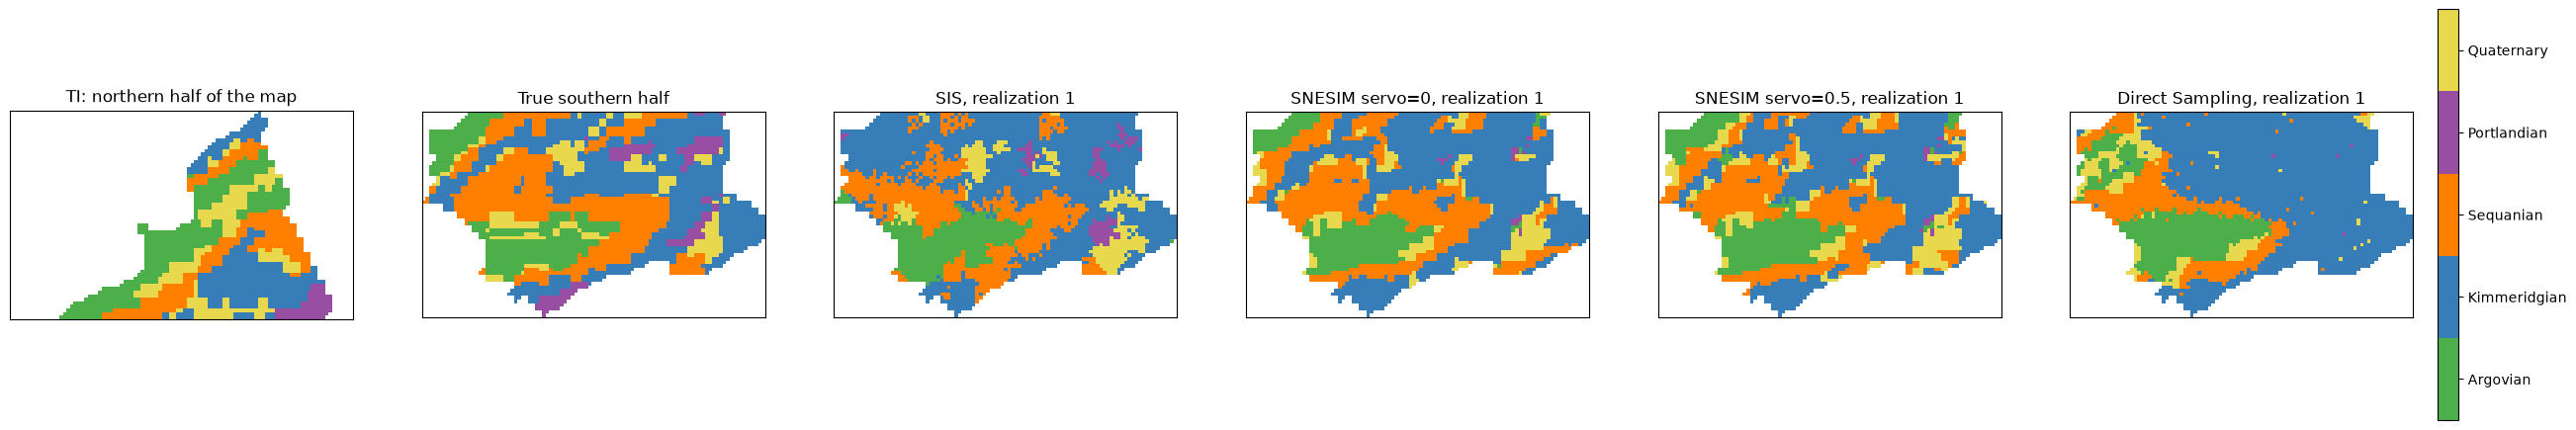

In [12]:
JC = ListedColormap(["#4daf4a", "#377eb8", "#ff7f00", "#984ea3", "#e7d84d"])


def show_jura(ax, values, title, extent_south=True):
    im = np.full((jimg.shape[0], CUT), np.nan)
    im[jx[south], jy[south]] = values
    h = ax.imshow(im.T, origin="lower", cmap=JC, vmin=0.5, vmax=5.5, interpolation="nearest")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    return h


fig, axes = plt.subplots(1, 6, figsize=(32, 5.4))
h = axes[0].imshow(TI_J.T, origin="lower", cmap=JC, vmin=0.5, vmax=5.5, interpolation="nearest")
axes[0].set_title("TI: northern half of the map")
axes[0].set_xticks([])
axes[0].set_yticks([])
show_jura(axes[1], s_truth, "True southern half")
for ax, (name, r) in zip(axes[2:], jura_reals.items()):
    show_jura(ax, r[0], f"{name}, realization 1")
cb = fig.colorbar(h, ax=axes, ticks=list(NAMES), fraction=0.01, pad=0.01)
cb.ax.set_yticklabels(list(NAMES.values()))
plt.show()

* **The TI is not representative.** The northern half has 29% Argovian and 26% Kimmeridgian; the true southern half has 15% and 39%. A real TI is rarely a perfect analogue, and this one also covers only 2,105 cells.
* **SNESIM with `servo = 0`** does best overall: 64% agreement per realization and 72% for the most probable unit. It has the most realistic boundary length (1,095 contact edges against the true 1,042), and its proportions follow the southern samples rather than the TI. It still produces about 29 Argovian-Kimmeridgian edges per realization, where the true south has none. Its small TI has few replicates of large data events, so they are reduced, and constraints are lost.
* **SNESIM with the default `servo = 0.5`** is close behind on agreement (63% per realization, 73% for the most probable unit), but it pulls the proportions toward the *northern* TI (Argovian 0.16 and Quaternary 0.14, against the true 0.15 and 0.11; Kimmeridgian 0.41). The boundaries are longer (1,192 contact edges, 35 Argovian-Kimmeridgian). Because only categories the TI allows are corrected, the servosystem itself creates no impossible patterns; an unmasked correction gave 337 Argovian-Kimmeridgian edges and twice the true boundary length here.
* **Direct Sampling** produces large, smooth patches (774 edges). It spreads Kimmeridgian over 61% of the area against the true 39%, and Sequanian and Portlandian shrink.
* **SIS** is competitive on cell agreement (62% and 70%), but it scatters units (71 Argovian-Kimmeridgian edges), as in the PGS notebook.

The lessons for real studies:

* Check that the TI is representative (proportions, unit sizes, stationarity) before simulating.
* Do not force a non-representative TI's proportions with the servosystem; use the target area's proportions (`target_proportions`) or `servo = 0`.
* Compare several simulators on held-out information.

Here the conditioning data were dense (217 samples), so they partly compensated for the TI's bias.

***
## Visualization of Uncertainty

Back to the channels: 20 conditional Direct Sampling realizations in sequence. Channels pinned by wells stay put; channels between wells move, appear and disappear. The probability map of Section 8 is the summary of this animation.

In [13]:
plt.rcParams["animation.embed_limit"] = 50
r_anim = cond["Direct Sampling"]
fig_anim, ax_anim = plt.subplots(figsize=(7, 7))
im_anim = ax_anim.imshow(r_anim[0].reshape(NX, NY).T, origin="lower", cmap=BIN, vmin=0, vmax=1, interpolation="nearest")
ax_anim.scatter(wells.X, wells.Y, c=np.where(wells.facies == 1, "red", "k"), s=12)
ax_anim.set_xticks([])
ax_anim.set_yticks([])
title_anim = ax_anim.set_title(f"Direct Sampling, realization 1 / {N_SIM}")


def _update(frame):
    im_anim.set_data(r_anim[frame].reshape(NX, NY).T)
    title_anim.set_text(f"Direct Sampling, realization {frame + 1} / {N_SIM}")
    return im_anim, title_anim


anim = FuncAnimation(fig_anim, _update, frames=N_SIM, interval=500, blit=False, repeat=True)
plt.close(fig_anim)
display(HTML(anim.to_jshtml()))

***
## CPU vs GPU Timing

Conditional simulation of the 100 × 100 channel field, for several `nsim`, on the CPU and the GPU. SNESIM's GPU engine gives the same realizations as the CPU engine, which is checked. Direct Sampling's GPU realizations are statistically equivalent rather than identical, so their channel proportion is compared instead.

In [14]:
rows = []
for name, make in [("SNESIM", lambda g: SNESIM(TI, servo=0.0, use_gpu=g)),
                   ("Direct Sampling", lambda g: DirectSampling(TI, use_gpu=g))]:
    for nsim in [1, 8, 32]:
        row = {"method": name, "nsim": nsim}
        t0 = time.perf_counter()
        out_cpu = make(False).fit(grid, wells, "X", "Y", "facies").simulate(nsim=nsim, seed=6)
        row["CPU (s)"] = time.perf_counter() - t0
        if USE_GPU:
            sim_g = make(True).fit(grid, wells, "X", "Y", "facies")
            sim_g.simulate(nsim=1, seed=0)                 # warm-up
            t0 = time.perf_counter()
            out_gpu = sim_g.simulate(nsim=nsim, seed=6)
            cp.cuda.Device(0).synchronize()
            row["GPU (s)"] = time.perf_counter() - t0
            row["speedup"] = row["CPU (s)"] / row["GPU (s)"]
            row["identical"] = bool(np.array_equal(out_cpu, out_gpu))
            row["channel prop. CPU / GPU"] = f"{out_cpu.mean():.3f} / {out_gpu.mean():.3f}"
        rows.append(row)
timing = pd.DataFrame(rows).set_index(["method", "nsim"])
display(timing.round(2))
if USE_GPU:
    record("SNESIM GPU = CPU realizations", "PASS" if timing.loc["SNESIM", "identical"].all() else "FAIL")

CPU (s)  GPU (s)  speedup  identical  \
method          nsim                                         
SNESIM          1        3.50     0.80     4.39       True   
                8       24.04     0.95    25.44       True   
                32      94.67     1.04    91.13       True   
Direct Sampling 1        1.60     1.14     1.41      False   
                8       13.11     2.82     4.65      False   
                32      53.28     4.77    11.18      False   

                     channel prop. CPU / GPU  
method          nsim                          
SNESIM          1              0.180 / 0.180  
                8              0.182 / 0.182  
                32             0.188 / 0.188  
Direct Sampling 1              0.122 / 0.122  
                8              0.134 / 0.130  
                32             0.134 / 0.133

✅ [PASS] SNESIM GPU = CPU realizations  


* **SNESIM:** the GPU engine gives **identical** realizations, and its speed-up grows with `nsim`: 4×, 25× and 88× for 1, 8 and 32 realizations. One kernel per step serves all realizations, so 32 realizations cost about the same as one (1.05 s against 0.80 s).
* **Direct Sampling:** speed-ups of 1.4×, 4.5× and 11×. Its GPU realizations are statistically equivalent but not identical to the CPU's (channel proportions 0.133 against 0.134 at 32 realizations).
* The CPU engines cost about 3 s (SNESIM) and 1.7 s (Direct Sampling) per realization on this 100 × 100 grid with 60 wells.

***
## Summary and Conclusions

In [15]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,"MPS (SNESIM, DS) more connected than SIS at 30...",PASS,"SIS 0.00, SNESIM 0.74, DS 0.67, TI 0.79"
1,SNESIM with servo=0 creates no forbidden A-C c...,PASS,0
2,SIS: wells honoured in every realization,PASS,
3,SNESIM: wells honoured in every realization,PASS,
4,Direct Sampling: wells honoured in every reali...,PASS,
5,co-simulation lowers the Brier score (DS and S...,PASS,DS 0.148 -> 0.058; SNESIM 0.148 -> 0.093
6,SNESIM GPU = CPU realizations,PASS,


- **Two-point statistics cannot describe channels.** SIS, given the TI's own variogram, produced disconnected blobs (connectivity 0 at 30 cells), while SNESIM and Direct Sampling reproduced the sinuous, connected channels of the training image (connectivity about 0.7, pattern-histogram distance 0.06-0.08 against 0.23 for SIS).
- **SNESIM** needs its **multigrid** for long structures (connectivity 0.002 with one level, 0.66 with four). Its **servosystem** controls proportions; because it corrects only categories the TI allows, it keeps the TI's adjacency rules (0.6 forbidden contacts per realization with the default `servo = 0.5`, from data-event reduction, against 389 for an unmasked correction).
- **Direct Sampling** needs no pattern database and handles **continuous** variables (TI histogram and patterns reproduced, slightly rougher at the finest lag). `threshold` and `n_neighbors` trade fidelity against speed; too large a threshold collapses the simulation.
- **Conditioning** to 60 wells was exact for all methods. MPS gave far better pattern and connectivity reproduction than SIS but only modestly better local probabilities. A **secondary variable** made the difference: Direct Sampling with a secondary TI recovered 77% of the channel cells, with the true connectivity (Brier 0.148 → 0.058); SNESIM with tau-model soft data improved less (0.093).
- **Real data:** with half of the Jura geology map as the TI, SNESIM (`servo = 0`) gave the best agreement per realization and boundary length, but the TI's different proportions and small size showed. The default servosystem pulled the proportions toward the non-representative TI. **Representative training images are the crux of MPS.**
- **GPU:** SNESIM's GPU engine is identical to the CPU and 88× faster at 32 realizations; Direct Sampling's is statistically equivalent and 11× faster.

| Object | Role in this notebook |
|---|---|
| `channel_training_image` | Synthetic channel TI and truth |
| `DirectSampling`, `dssim` | Categorical and continuous MPS; secondary TI co-simulation |
| `SNESIM`, `snesim` | Categorical MPS with multigrid, servosystem, tau-model soft data |
| `tau_model` | Combination of TI and soft probabilities |
| `pattern_histogram`, `pattern_histogram_distance`, `connectivity` | Pattern and connectivity diagnostics |
| `IndicatorCoSimulator` | Two-point (SIS) comparison |

### Choosing the options

| Situation | Choice |
|---|---|
| Curvilinear, connected structures (channels, fractures, drainage) | MPS; SIS cannot reproduce connectivity |
| Continuous variable with non-Gaussian patterns | `DirectSampling(kind="continuous")` |
| Strict adjacency rules in the TI must hold | SNESIM (the servosystem respects them) or Direct Sampling; check contacts |
| Proportions must match a target | SNESIM servosystem with `target_proportions`, or post-check and adjust the TI |
| Exhaustive secondary data | DS with `secondary_ti`, or SNESIM with soft probabilities and the tau model |
| Many realizations | `use_gpu=True` |
| A real TI | check that it is representative of the target area (proportions, scales, stationarity) before trusting MPS |

***
## References

| Reference | Used for |
|---|---|
| Guardiano, F.B. & Srivastava, R.M. (1993). Multivariate geostatistics: beyond bivariate moments. In Soares, A. (ed.), *Geostatistics Tróia '92*, 133-144. Kluwer. | The single normal equation / MPS principle |
| Strebelle, S. (2002). Conditional simulation of complex geological structures using multiple-point statistics. *Mathematical Geology* 34, 1-21. | SNESIM |
| Mariethoz, G., Renard, P. & Straubhaar, J. (2010). The Direct Sampling method to perform multiple-point geostatistical simulations. *Water Resources Research* 46, W11536. | Direct Sampling |
| Straubhaar, J., Renard, P., Mariethoz, G., Froidevaux, R. & Besson, O. (2011). An improved parallel multiple-point algorithm using a list approach. *Mathematical Geosciences* 43, 305-328. | List-based pattern storage (IMPALA) |
| Journel, A.G. (2002). Combining knowledge from diverse sources: an alternative to traditional data independence hypotheses. *Mathematical Geology* 34, 573-596. | The tau model |
| Mariethoz, G. & Caers, J. (2014). *Multiple-Point Geostatistics: Stochastic Modeling with Training Images*. Wiley-Blackwell. | MPS overview, diagnostics, TI selection |
| Renard, P. & Allard, D. (2013). Connectivity metrics for subsurface flow and transport. *Advances in Water Resources* 51, 168-196. | Connectivity function |
| Atteia, O., Dubois, J.-P. & Webster, R. (1994). Geostatistical analysis of soil contamination in the Swiss Jura. *Environmental Pollution* 86, 315-327. | The Jura data |